# BÀI THI GIỮA KỲ – Phân tích và Trực quan Dữ liệu
**Dữ liệu:** winequality-red.csv (UCI Machine Learning Repository)

In [3]:
# Cài thư viện squarify (dùng cho Treemap) nếu chưa có
!pip install squarify -q

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import squarify

sns.set_theme(style="whitegrid")


[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: C:\Users\jakbr\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


## Phần 1: Xử lý dữ liệu
### Câu 1: Đọc file và hiển thị 5 dòng đầu

In [4]:
# File dùng dấu ';' làm dấu phân cách.
# Ưu tiên đọc file cục bộ (đặt cùng thư mục / upload lên Colab); nếu không có thì tải từ UCI
import os
path = "winequality-red.csv"
if not os.path.exists(path):
    path = "https://archive.ics.uci.edu/ml/machine-learning-databases/wine-quality/winequality-red.csv"
df = pd.read_csv(path, sep=";")
print("Kích thước dữ liệu:", df.shape)
df.head()

Kích thước dữ liệu: (1599, 12)


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5


### Câu 2: Trung bình, nhỏ nhất, lớn nhất của các cột số

In [5]:
# Cách 1: chọn cụ thể mean, min, max
df.select_dtypes(include="number").agg(["mean", "min", "max"]).T

,mean,min,max
fixed acidity,8.319637,4.60000,15.90000
volatile acidity,0.527821,0.12000,1.58000
citric acid,0.270976,0.00000,1.00000
residual sugar,2.538806,0.90000,15.50000
chlorides,0.087467,0.01200,0.61100
free sulfur dioxide,15.874922,1.00000,72.00000
total sulfur dioxide,46.467792,6.00000,289.00000
density,0.996747,0.99007,1.00369
pH,3.311113,2.74000,4.01000
sulphates,0.658149,0.33000,2.00000


In [6]:
# Cách 2: describe() (đầy đủ hơn)
df.describe()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
count,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000
mean,8.319637,0.527821,0.270976,2.538806,0.087467,15.874922,46.467792,0.996747,3.311113,0.658149,10.422983,5.636023
std,1.741096,0.179060,0.194801,1.409928,0.047065,10.460157,32.895324,0.001887,0.154386,0.169507,1.065668,0.807569
min,4.600000,0.120000,0.000000,0.900000,0.012000,1.000000,6.000000,0.990070,2.740000,0.330000,8.400000,3.000000
25%,7.100000,0.390000,0.090000,1.900000,0.070000,7.000000,22.000000,0.995600,3.210000,0.550000,9.500000,5.000000
50%,7.900000,0.520000,0.260000,2.200000,0.079000,14.000000,38.000000,0.996750,3.310000,0.620000,10.200000,6.000000
75%,9.200000,0.640000,0.420000,2.600000,0.090000,21.000000,62.000000,0.997835,3.400000,0.730000,11.100000,6.000000
max,15.900000,1.580000,1.000000,15.500000,0.611000,72.000000,289.000000,1.003690,4.010000,2.000000,14.900000,8.000000


## Phần 2: Trực quan hóa dữ liệu
### Câu 3: Histogram của `alcohol` (20 bins)

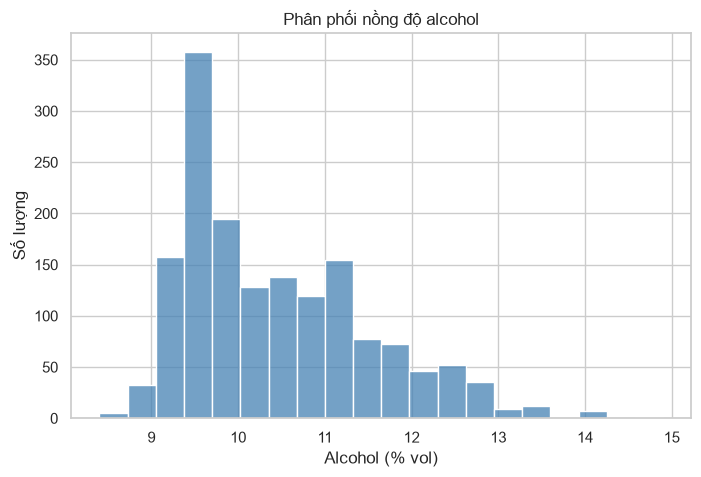

In [7]:
plt.figure(figsize=(8, 5))
sns.histplot(df["alcohol"], bins=20, color="steelblue")
plt.title("Phân phối nồng độ alcohol")
plt.xlabel("Alcohol (% vol)")
plt.ylabel("Số lượng")
plt.show()

### Câu 4: Boxplot `volatile acidity` theo `quality`

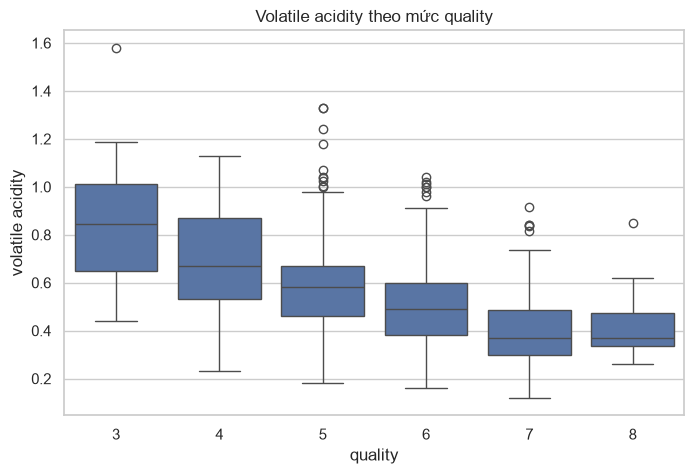

In [8]:
plt.figure(figsize=(8, 5))
sns.boxplot(x="quality", y="volatile acidity", data=df)
plt.title("Volatile acidity theo mức quality")
plt.show()

### Câu 5: Scatter plot `alcohol` – `density`, màu theo `quality`

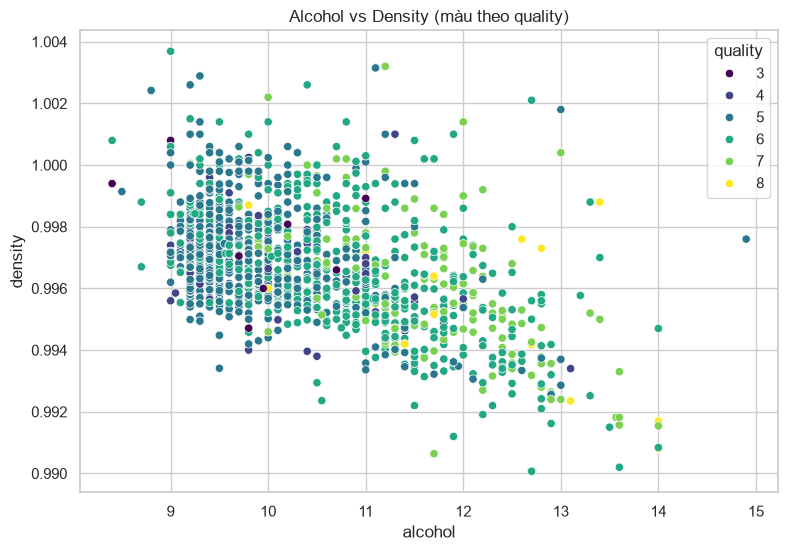

In [9]:
plt.figure(figsize=(9, 6))
sns.scatterplot(x="alcohol", y="density", hue="quality", palette="viridis", data=df)
plt.title("Alcohol vs Density (màu theo quality)")
plt.show()

### Câu 6: Treemap tổng `alcohol` theo `quality`

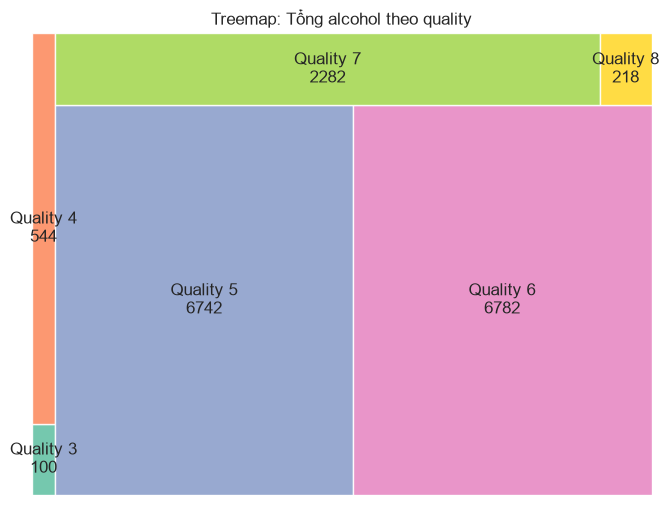

In [10]:
alc_sum = df.groupby("quality")["alcohol"].sum()
labels = [f"Quality {q}\n{v:.0f}" for q, v in alc_sum.items()]

plt.figure(figsize=(8, 6))
squarify.plot(sizes=alc_sum.values, label=labels,
              color=sns.color_palette("Set2", len(alc_sum)), alpha=0.9)
plt.title("Treemap: Tổng alcohol theo quality")
plt.axis("off")
plt.show()

### Câu 7: Biểu đồ Pie – tỷ lệ số dòng theo `quality`

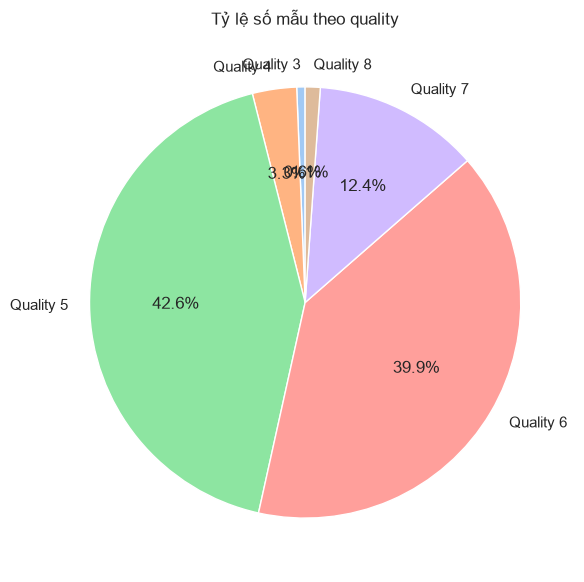

In [11]:
counts = df["quality"].value_counts().sort_index()

plt.figure(figsize=(7, 7))
plt.pie(counts.values, labels=[f"Quality {q}" for q in counts.index],
        autopct="%1.1f%%", startangle=90, colors=sns.color_palette("pastel"))
plt.title("Tỷ lệ số mẫu theo quality")
plt.show()

### Câu 8: Biểu đồ cột ngang – tổng `sulphates` theo `quality`

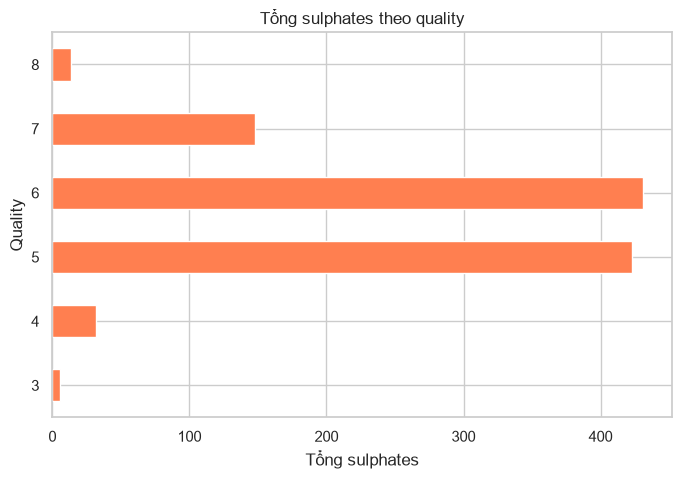

In [12]:
plt.figure(figsize=(8, 5))
df.groupby("quality")["sulphates"].sum().plot(kind="barh", color="coral")
plt.title("Tổng sulphates theo quality")
plt.xlabel("Tổng sulphates")
plt.ylabel("Quality")
plt.show()

## Phần 3: Nhận xét kết quả
### Câu 9

In [13]:
# Kiểm chứng bằng số liệu: trung bình volatile acidity theo quality
df.groupby("quality")["volatile acidity"].mean().round(3)

quality
3    0.885
4    0.694
5    0.577
6    0.497
7    0.404
8    0.423
Name: volatile acidity, dtype: float64

**Trả lời:** Rượu **chất lượng 3** có độ acid bay hơi trung bình cao nhất (**0.885** g/dm³).

Xu hướng chung: quality tăng thì volatile acidity giảm: 0.694 (quality 4), 0.577 (5), 0.497 (6), 0.404 (7); quality 8 là 0.423 (nhỉnh hơn quality 7 một chút). Acid bay hơi cao tạo mùi giấm khó chịu nên làm giảm chất lượng rượu.

### Câu 10

In [14]:
# Kiểm chứng: trung bình alcohol theo quality và tương quan với quality
print(df.groupby("quality")["alcohol"].mean().round(2))
print("Tương quan alcohol - quality:", round(df["alcohol"].corr(df["quality"]), 3))
print("Tương quan alcohol - density:", round(df["alcohol"].corr(df["density"]), 3))

quality
3     9.96
4    10.27
5     9.90
6    10.63
7    11.47
8    12.09
Name: alcohol, dtype: float64
Tương quan alcohol - quality: 0.476
Tương quan alcohol - density: -0.496


**Trả lời:** Rượu chất lượng cao có xu hướng chứa **nhiều alcohol hơn**. Các điểm màu đậm (quality 7–8) tập trung ở vùng alcohol cao (~11–13%), còn quality 5 tập trung ở vùng ~9–10%.

Số liệu: alcohol trung bình theo quality là 9.90 (quality 5), 10.63 (6), 11.47 (7), 12.09 (8); hệ số tương quan alcohol–quality = **+0.476**. (Quality 3 và 4 có rất ít mẫu nên trung bình dao động: 9.96 và 10.27.)

**Vì sao:** (1) Rượu có alcohol cao thường được làm từ nho chín hơn, nhiều đường, cho hương vị đậm đà, cân bằng hơn nên được chấm điểm cao. (2) Trên scatter plot, alcohol tăng thì density giảm (tương quan alcohol–density = **-0.496**) vì ethanol nhẹ hơn nước, nên rượu chất lượng cao cũng thường có density thấp. (Lưu ý: đây là tương quan, chưa chứng minh nhân quả.)